# Линейная и логистическая регрессия: от интуиции к практике

Обучающий notebook по двум базовым моделям машинного обучения. Несмотря на похожие названия, они решают разные задачи:

- **линейная регрессия** прогнозирует числовую величину;
- **логистическая регрессия** оценивает вероятность класса и используется для классификации.

Все примеры самодостаточны: данные создаются кодом, внешние файлы и интернет не нужны.

## Чему вы научитесь

- формулировать задачу и выбирать подходящую модель;
- разделять данные на обучающую и тестовую выборки;
- обучать модели через `scikit-learn`;
- считать и интерпретировать метрики;
- строить простые baseline-модели;
- анализировать ошибки, коэффициенты и порог классификации;
- использовать `Pipeline`, регуляризацию и полиномиальные признаки.

## Как работать с материалом

1. Запускайте ячейки последовательно.
2. После каждого примера попробуйте изменить один параметр и объяснить, что изменилось.
3. Не запоминайте только функции — сначала отвечайте на вопрос: «Что означает результат для задачи?»
4. После обучения перейдите к файлу с практикой. Решения находятся в отдельном notebook’е.


## 0. Подготовка

Нужны стандартные библиотеки для анализа данных: `numpy`, `pandas`, `matplotlib` и `scikit-learn`.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.datasets import make_regression, make_classification
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, log_loss, confusion_matrix,
    classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay
)

RANDOM_STATE = 42
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
print('Библиотеки загружены')


Библиотеки загружены


# Часть 1. Линейная регрессия

## 1.1. Идея модели

Для одного признака модель задаёт прямую:

$$\hat{y} = b_0 + b_1 x.$$

Для нескольких признаков:

$$\hat{y} = b_0 + b_1x_1 + \dots + b_px_p.$$

Здесь $\hat{y}$ — прогноз, $b_0$ — свободный член, а $b_j$ — изменение ожидаемого прогноза при увеличении $x_j$ на единицу **при неизменных остальных признаках**.

Обучение обычной линейной регрессии минимизирует сумму квадратов ошибок:

$$\operatorname{MSE} = \frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2.$$

Квадрат ошибки делает большие промахи особенно «дорогими». Модель линейна **по коэффициентам**, но сами признаки могут быть нелинейными преобразованиями исходных переменных, например $x^2$.


## 1.2. Создаём синтетические данные

Сначала рассмотрим один признак, чтобы визуализировать модель. Шум добавлен специально: реальные наблюдения почти никогда не ложатся идеально на прямую.


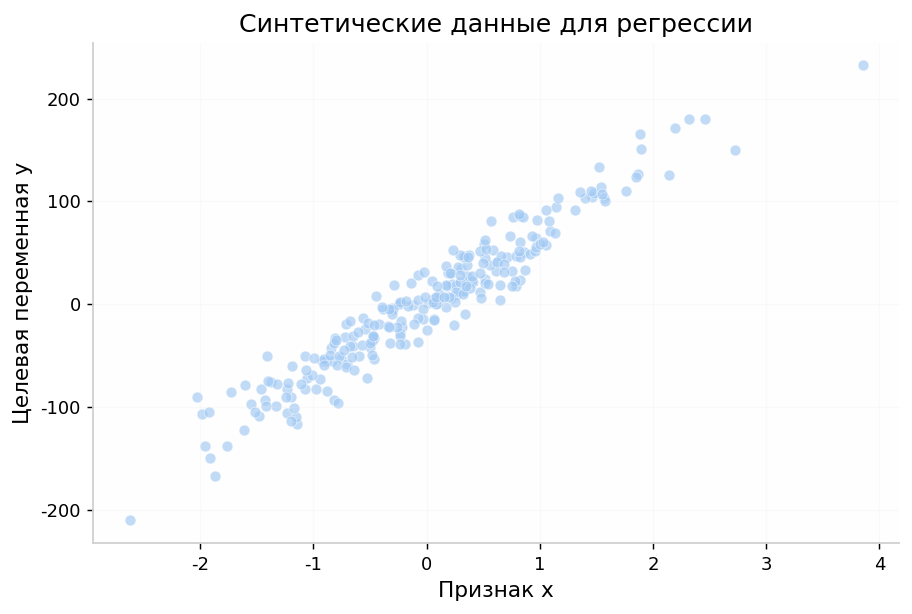

In [2]:
X, y = make_regression(
    n_samples=250,
    n_features=1,
    noise=18,
    random_state=RANDOM_STATE
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X[:, 0], y, alpha=0.65, edgecolor='white', linewidth=0.4)
ax.set(title='Синтетические данные для регрессии', xlabel='Признак x', ylabel='Целевая переменная y')
ax.grid(alpha=0.2)
plt.show()


## 1.3. Train/test split и baseline

**Обучающая выборка** нужна для подбора параметров, **тестовая** — для итоговой проверки на данных, которые модель не видела.

Сначала создадим baseline: модель, которая всегда прогнозирует среднее значение `y_train`. Если сложная модель не лучше такого baseline, её практическая ценность сомнительна.


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE
)

baseline_reg = DummyRegressor(strategy='mean')
baseline_reg.fit(X_train, y_train)
y_pred_baseline = baseline_reg.predict(X_test)

print('Размер train:', X_train.shape[0])
print('Размер test: ', X_test.shape[0])
print('Baseline MAE:', round(mean_absolute_error(y_test, y_pred_baseline), 3))
print('Baseline R²: ', round(r2_score(y_test, y_pred_baseline), 3))


Размер train: 187
Размер test:  63
Baseline MAE: 56.919
Baseline R²:  -0.013


## 1.4. Обучение линейной регрессии

Три основных шага в `scikit-learn`:

1. создать модель;
2. вызвать `fit(X_train, y_train)`;
3. получить прогноз через `predict(X_test)`.


Свободный член b0: 1.814
Коэффициент b1:    67.317


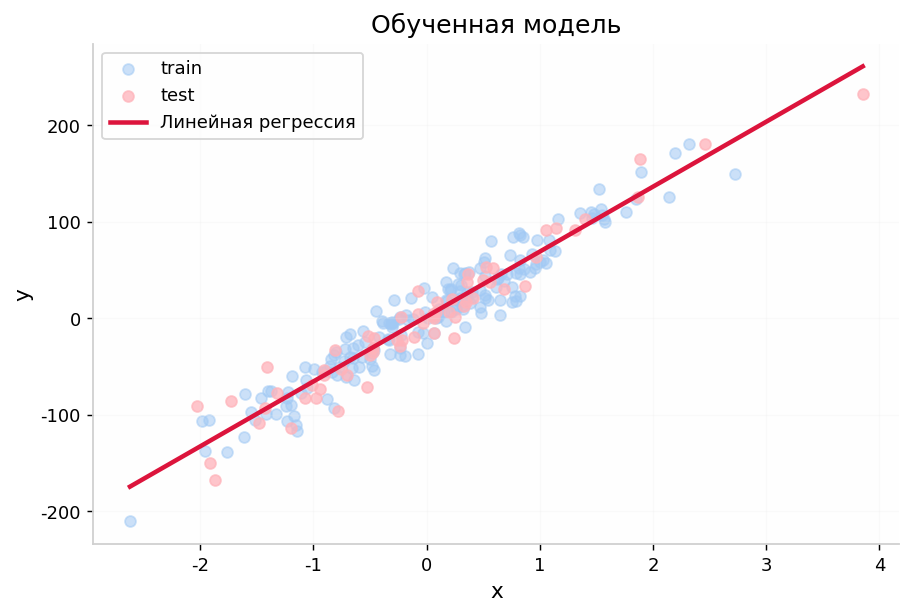

In [4]:
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_pred = lin_reg.predict(X_test)

print(f'Свободный член b0: {lin_reg.intercept_:.3f}')
print(f'Коэффициент b1:    {lin_reg.coef_[0]:.3f}')

x_line = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)
y_line = lin_reg.predict(x_line)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X_train[:, 0], y_train, alpha=0.55, label='train')
ax.scatter(X_test[:, 0], y_test, alpha=0.75, label='test')
ax.plot(x_line[:, 0], y_line, color='crimson', linewidth=2.5, label='Линейная регрессия')
ax.set(title='Обученная модель', xlabel='x', ylabel='y')
ax.legend()
ax.grid(alpha=0.2)
plt.show()


## 1.5. Метрики регрессии

Пусть ошибка наблюдения равна $e_i=y_i-\hat{y}_i$.

- **MAE** — средний модуль ошибки. Легко интерпретировать в единицах целевой переменной.
- **RMSE** — корень из среднего квадрата ошибки. Тоже измеряется в единицах $y$, но сильнее штрафует крупные ошибки.
- **$R^2$** — доля дисперсии, объяснённая моделью относительно прогноза средним. Значение 1 — идеально, 0 — примерно уровень baseline на тех же данных, отрицательное значение — хуже baseline.

Формулы:

$$\operatorname{MAE}=\frac1n\sum_i|e_i|,\qquad
\operatorname{RMSE}=\sqrt{\frac1n\sum_i e_i^2}.$$

Одной метрики обычно недостаточно: выбирайте её с учётом стоимости ошибок в конкретной задаче.


In [5]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mse),
        'R2': r2_score(y_true, y_pred)
    }

metrics_comparison = pd.DataFrame({
    'Baseline': regression_metrics(y_test, y_pred_baseline),
    'LinearRegression': regression_metrics(y_test, y_pred)
}).T

display(metrics_comparison.round(3))


,MAE,RMSE,R2
Baseline,56.9190,75.2350,-0.0130
LinearRegression,14.5010,19.0160,0.9350


## 1.6. Анализ остатков

**Остаток** — это $y-\hat{y}$. Полезно проверить:

- нет ли явной изогнутой закономерности в остатках;
- растёт ли разброс ошибок с увеличением прогноза;
- есть ли отдельные сильные выбросы.

Для хорошо подобранной простой модели остатки часто выглядят как случайное облако вокруг нуля. Это эвристика, а не полноценная проверка всех статистических допущений.


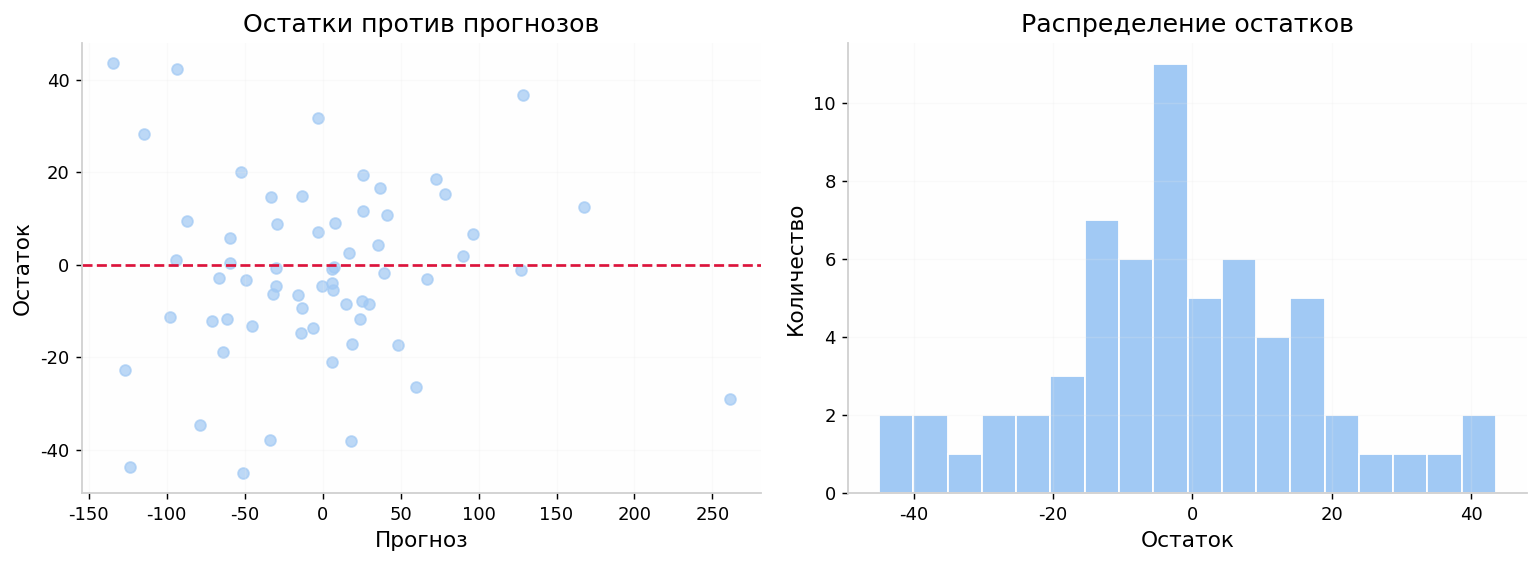

In [6]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_pred, residuals, alpha=0.7)
axes[0].axhline(0, color='crimson', linestyle='--')
axes[0].set(title='Остатки против прогнозов', xlabel='Прогноз', ylabel='Остаток')
axes[0].grid(alpha=0.2)

axes[1].hist(residuals, bins=18, edgecolor='white')
axes[1].set(title='Распределение остатков', xlabel='Остаток', ylabel='Количество')
axes[1].grid(alpha=0.2)
plt.tight_layout()
plt.show()


## 1.7. Несколько признаков и интерпретация коэффициентов

Сравним три модели:

- `LinearRegression` — без регуляризации;
- `Ridge` — добавляет штраф за большие коэффициенты через $L_2$-норму;
- `Lasso` — использует $L_1$-штраф и может обращать некоторые коэффициенты в ноль.

Перед регуляризацией признаки масштабируют, иначе штраф может зависеть от единиц измерения. `Pipeline` гарантирует, что `StandardScaler` обучается только на обучающей выборке.


In [7]:
X_multi, y_multi = make_regression(
    n_samples=400,
    n_features=8,
    n_informative=5,
    noise=25,
    random_state=11
)
feature_names = [f'x{i+1}' for i in range(X_multi.shape[1])]
Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    X_multi, y_multi, test_size=0.25, random_state=RANDOM_STATE
)

models = {
    'LinearRegression': LinearRegression(),
    'Ridge': Pipeline([
        ('scaler', StandardScaler()),
        ('model', Ridge(alpha=10.0))
    ]),
    'Lasso': Pipeline([
        ('scaler', StandardScaler()),
        ('model', Lasso(alpha=1.0, max_iter=20_000))
    ])
}

rows = []
for name, model in models.items():
    model.fit(Xm_train, ym_train)
    pred = model.predict(Xm_test)
    rows.append({'model': name, **regression_metrics(ym_test, pred)})

multi_results = pd.DataFrame(rows).set_index('model')
display(multi_results.round(3))


,MAE,RMSE,R2
model,,,
LinearRegression,19.6170,25.4360,0.9620
Ridge,20.2990,25.9270,0.9610
Lasso,19.6760,25.4560,0.9620


,Коэффициент Ridge
x1,97.8690
x7,60.8110
x8,59.8430
x6,32.8670
x2,13.8270
x4,1.9140
x5,0.2550
x3,0.0120


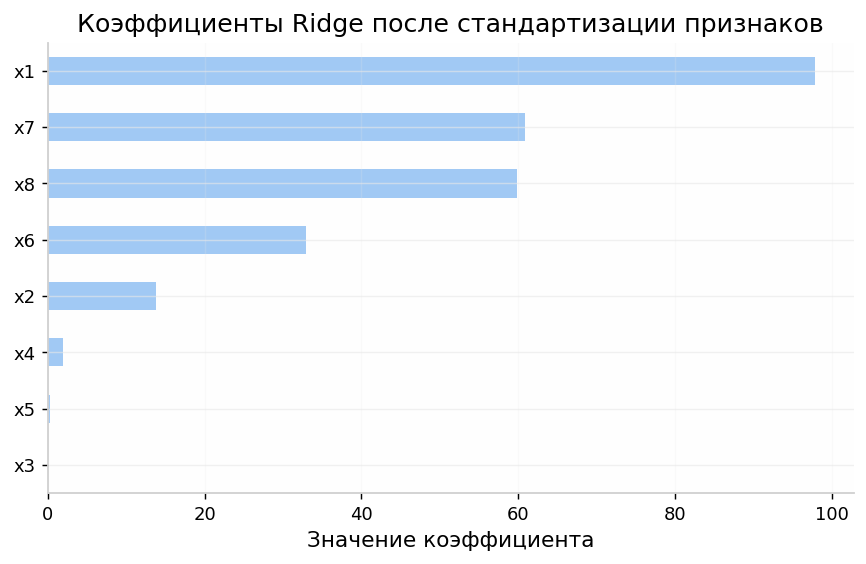

In [8]:
ridge_coefs = pd.Series(
    models['Ridge'].named_steps['model'].coef_,
    index=feature_names,
    name='Коэффициент Ridge'
).sort_values(key=np.abs, ascending=False)

display(ridge_coefs.to_frame().round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
ridge_coefs.sort_values().plot(kind='barh', ax=ax)
ax.set(title='Коэффициенты Ridge после стандартизации признаков', xlabel='Значение коэффициента')
ax.grid(axis='x', alpha=0.2)
plt.show()


**Как читать коэффициенты после стандартизации:** они показывают изменение прогноза при изменении стандартизованного признака на единицу, то есть примерно на одно его стандартное отклонение, при фиксированных остальных признаках.

Большой модуль коэффициента не доказывает причинность. На оценки влияют корреляции между признаками, шум, выбросы и спецификация модели.

Параметр `alpha` управляет силой регуляризации: чем он больше, тем сильнее сжатие коэффициентов. Его следует выбирать по кросс-валидации, а не по тестовой выборке.


## 1.8. Полиномиальные признаки: линейная модель описывает кривую

Если связь нелинейна, можно добавить $x^2, x^3,\ldots$ как новые признаки. Модель остаётся линейной по коэффициентам:

$$\hat{y}=b_0+b_1x+b_2x^2.$$

Слишком высокая степень полинома способна запомнить шум и ухудшить обобщение.


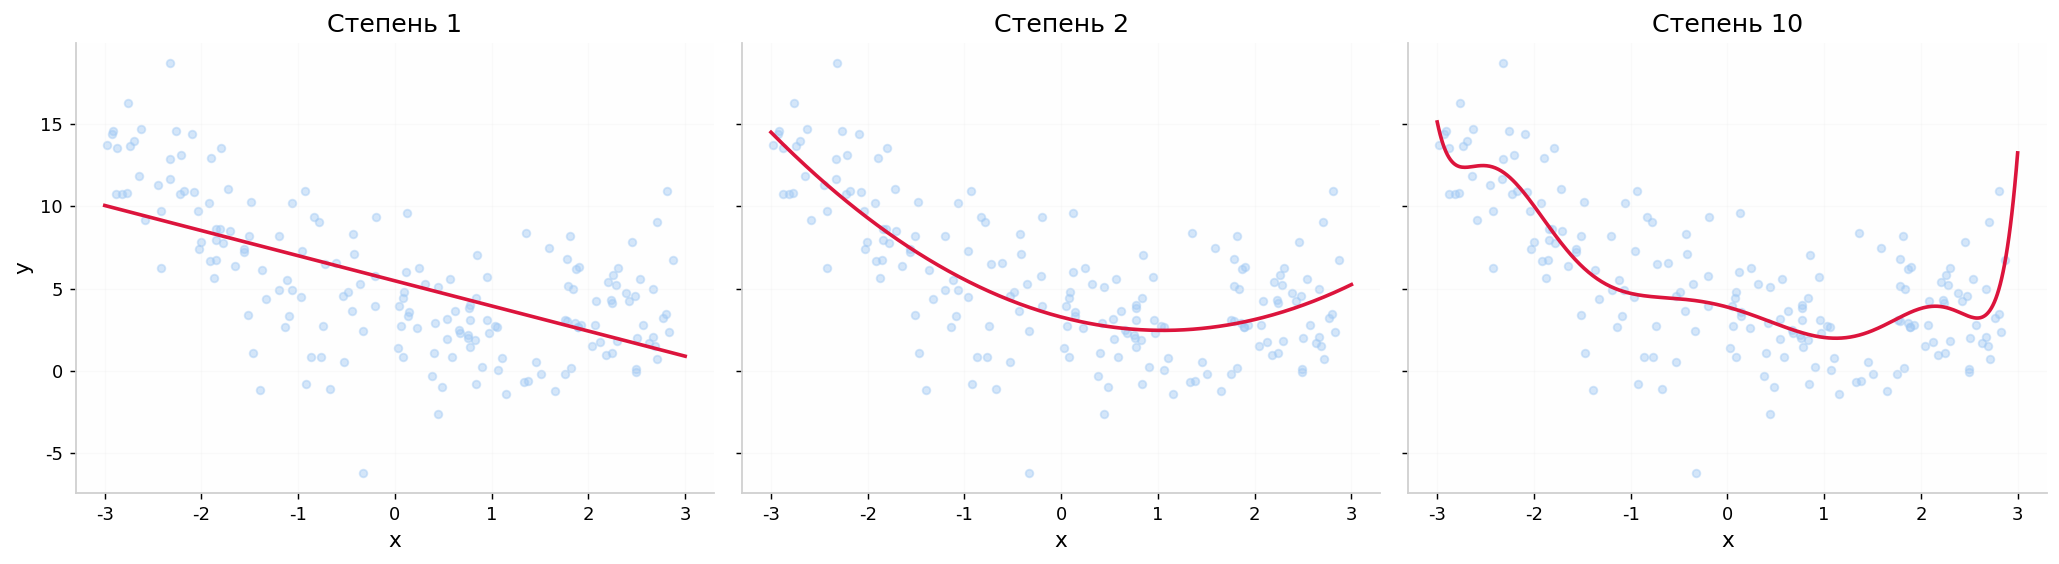

,MAE,RMSE,R2
degree,,,
1,3.4640,4.1290,0.3380
2,2.2300,2.7650,0.7030
10,2.2260,2.7600,0.7040


In [9]:
rng = np.random.default_rng(7)
x_curve = rng.uniform(-3, 3, size=240)
y_curve = 0.9 * x_curve**2 - 1.4 * x_curve + 3 + rng.normal(0, 3, size=240)
x_curve = x_curve.reshape(-1, 1)

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    x_curve, y_curve, test_size=0.25, random_state=RANDOM_STATE
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
grid = np.linspace(-3, 3, 400).reshape(-1, 1)
curve_rows = []

for ax, degree in zip(axes, [1, 2, 10]):
    curve_model = Pipeline([
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('model', LinearRegression())
    ])
    curve_model.fit(Xc_train, yc_train)
    pred = curve_model.predict(Xc_test)
    curve_rows.append({'degree': degree, **regression_metrics(yc_test, pred)})

    ax.scatter(Xc_train[:, 0], yc_train, s=18, alpha=0.45, label='train')
    ax.plot(grid[:, 0], curve_model.predict(grid), color='crimson', linewidth=2)
    ax.set(title=f'Степень {degree}', xlabel='x')
    ax.grid(alpha=0.2)
axes[0].set_ylabel('y')
plt.tight_layout()
plt.show()

display(pd.DataFrame(curve_rows).set_index('degree').round(3))


# Часть 2. Логистическая регрессия

## 2.1. От линейной комбинации к вероятности

Для бинарной классификации логистическая регрессия моделирует вероятность класса 1:

$$z=b_0+b_1x_1+\dots+b_px_p,$$
$$p(y=1\mid x)=\sigma(z)=\frac{1}{1+e^{-z}}.$$

Сигмоида переводит любое действительное число $z$ в диапазон $(0,1)$. Модель обучается минимизацией **логистической потери** (`log loss`), а не MSE.

В терминах шансов:

$$\log\frac{p}{1-p}=z.$$

Поэтому $e^{b_j}$ — мультипликативное изменение шансов класса 1 при увеличении $x_j$ на единицу при прочих равных. Это **не** изменение вероятности на фиксированное число процентных пунктов.


## 2.2. Данные и разбиение

Создадим два признака и два класса. `stratify=y` сохраняет примерно одинаковую долю классов в train и test.


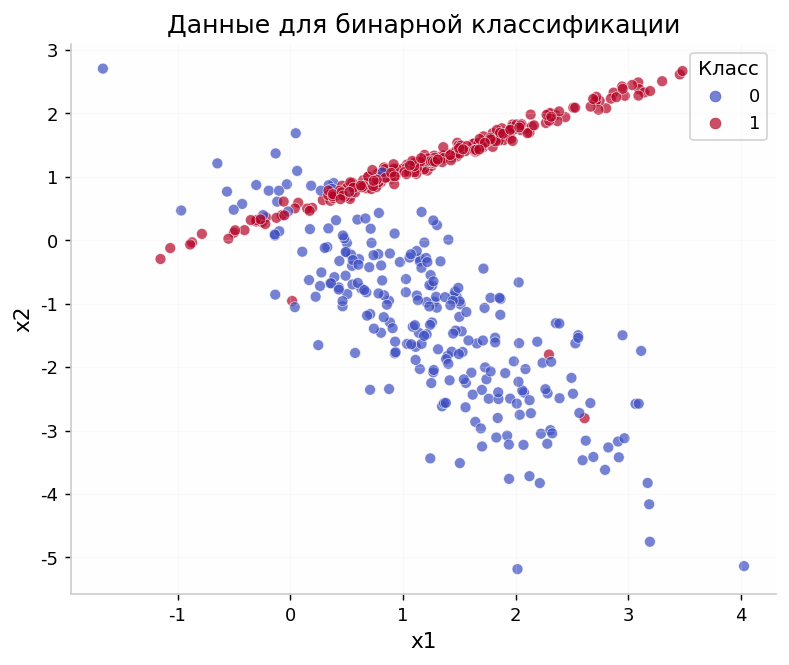

In [10]:
X_clf, y_clf = make_classification(
    n_samples=500,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    n_clusters_per_class=1,
    class_sep=1.25,
    flip_y=0.03,
    random_state=RANDOM_STATE
)

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_clf, y_clf,
    test_size=0.25,
    stratify=y_clf,
    random_state=RANDOM_STATE
)

fig, ax = plt.subplots(figsize=(7, 5.5))
scatter = ax.scatter(X_clf[:, 0], X_clf[:, 1], c=y_clf, cmap='coolwarm', alpha=0.7, edgecolor='white', linewidth=0.4)
ax.set(title='Данные для бинарной классификации', xlabel='x1', ylabel='x2')
ax.legend(*scatter.legend_elements(), title='Класс')
ax.grid(alpha=0.2)
plt.show()


## 2.3. Baseline и обучение модели

Для классификации baseline может всегда выбирать самый частый класс. Это особенно важно при дисбалансе: высокая accuracy может ничего не говорить о качестве обнаружения редкого класса.

Логистическую регрессию обычно используют со стандартизацией признаков. Параметр `C` обратно связан с силой $L_2$-регуляризации: меньше `C` — сильнее регуляризация.


In [11]:
baseline_clf = DummyClassifier(strategy='most_frequent')
baseline_clf.fit(Xc_train, yc_train)
baseline_pred = baseline_clf.predict(Xc_test)

log_reg = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(C=1.0, max_iter=2000, random_state=RANDOM_STATE))
])
log_reg.fit(Xc_train, yc_train)

y_pred_clf = log_reg.predict(Xc_test)
y_proba = log_reg.predict_proba(Xc_test)[:, 1]

print('Baseline accuracy:', round(accuracy_score(yc_test, baseline_pred), 3))
print('Model accuracy:   ', round(accuracy_score(yc_test, y_pred_clf), 3))
print('Первые 5 вероятностей класса 1:', np.round(y_proba[:5], 3))


Baseline accuracy: 0.504
Model accuracy:    0.92
Первые 5 вероятностей класса 1: [0.933 0.054 0.993 0.983 0.818]


## 2.4. Метрики классификации

Матрица ошибок для класса 1:

| | Прогноз 0 | Прогноз 1 |
|---|---:|---:|
| **Факт 0** | TN | FP |
| **Факт 1** | FN | TP |

- **Accuracy** $=(TP+TN)/(TP+TN+FP+FN)$ — общая доля верных ответов.
- **Precision** $=TP/(TP+FP)$ — какая доля положительных прогнозов верна.
- **Recall** $=TP/(TP+FN)$ — какая доля фактических объектов класса 1 найдена.
- **F1** — гармоническое среднее precision и recall.
- **Balanced accuracy** — среднее recall по классам; полезна при дисбалансе.
- **ROC AUC** — качество ранжирования объектов по вероятности, усреднённое по порогам.
- **Log loss** — штрафует уверенные неверные вероятности; чем меньше, тем лучше.

Метрику выбирают по цене FP и FN. Например, при скрининге заболевания пропуск класса 1 может быть дороже ложной тревоги.


,LogisticRegression
accuracy,0.9200
balanced_accuracy,0.9200
precision,0.8960
recall,0.9520
f1,0.9230
roc_auc,0.9830
log_loss,0.1940


              precision    recall  f1-score   support

           0      0.948     0.887     0.917        62
           1      0.896     0.952     0.923        63

    accuracy                          0.920       125
   macro avg      0.922     0.920     0.920       125
weighted avg      0.922     0.920     0.920       125



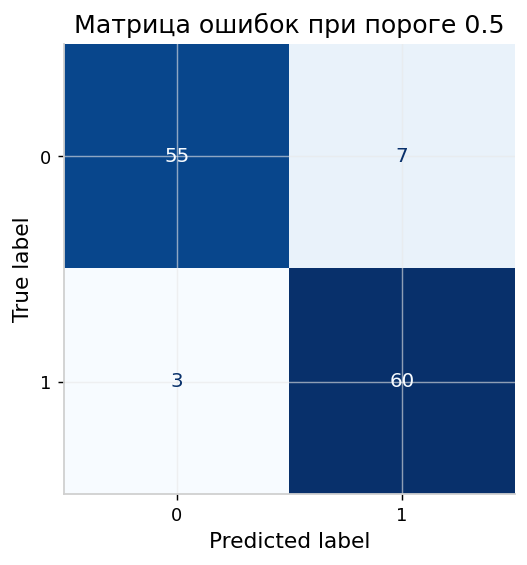

In [12]:
def classification_metrics(y_true, y_pred, y_score):
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'roc_auc': roc_auc_score(y_true, y_score),
        'log_loss': log_loss(y_true, y_score)
    }

clf_metrics = classification_metrics(yc_test, y_pred_clf, y_proba)
display(pd.Series(clf_metrics, name='LogisticRegression').to_frame().round(3))

print(classification_report(yc_test, y_pred_clf, digits=3, zero_division=0))

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(yc_test, y_pred_clf, cmap='Blues', colorbar=False, ax=ax)
ax.set_title('Матрица ошибок при пороге 0.5')
plt.show()


## 2.5. Граница решения

При пороге 0.5 граница решения соответствует $p=0.5$, то есть $z=0$. Для двух признаков это линия в пространстве исходных признаков.


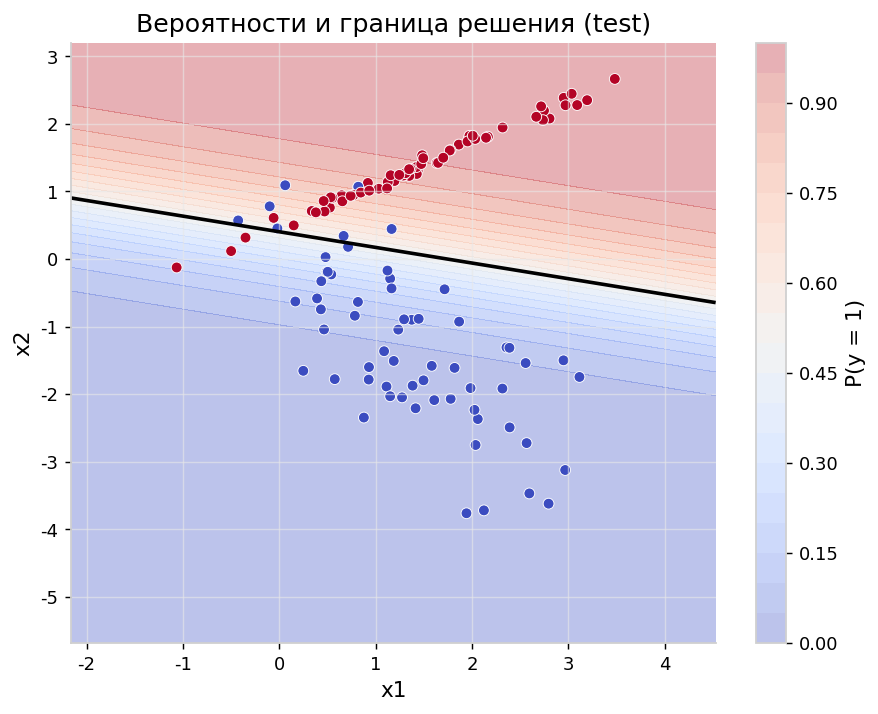

In [13]:
xx, yy = np.meshgrid(
    np.linspace(X_clf[:, 0].min() - 0.5, X_clf[:, 0].max() + 0.5, 300),
    np.linspace(X_clf[:, 1].min() - 0.5, X_clf[:, 1].max() + 0.5, 300)
)
grid_points = np.c_[xx.ravel(), yy.ravel()]
grid_proba = log_reg.predict_proba(grid_points)[:, 1].reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8, 6))
contour = ax.contourf(xx, yy, grid_proba, levels=20, cmap='coolwarm', alpha=0.35)
ax.contour(xx, yy, grid_proba, levels=[0.5], colors='black', linewidths=2)
scatter = ax.scatter(Xc_test[:, 0], Xc_test[:, 1], c=yc_test, cmap='coolwarm', edgecolor='white', linewidth=0.5)
fig.colorbar(contour, ax=ax, label='P(y = 1)')
ax.set(title='Вероятности и граница решения (test)', xlabel='x1', ylabel='x2')
plt.show()


## 2.6. ROC и Precision–Recall

Эти кривые показывают качество при разных порогах. ROC AUC не зависит от одного выбранного порога, но при сильном дисбалансе дополнительно полезен Precision–Recall AUC и анализ конкретной рабочей точки.


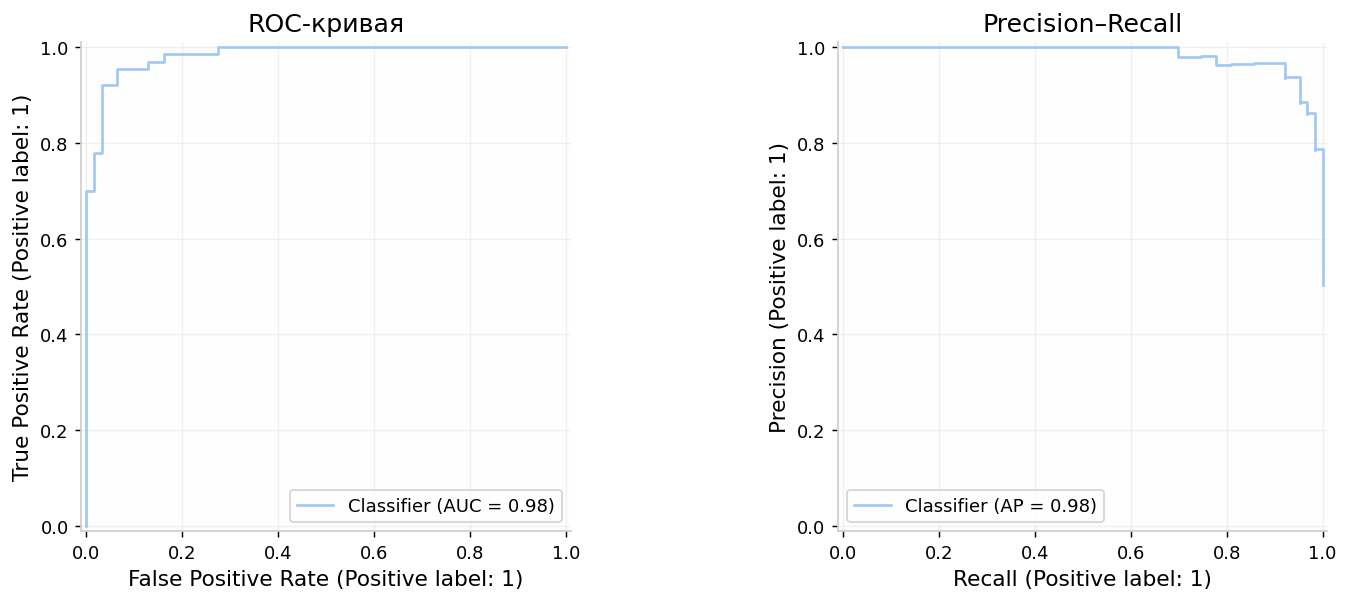

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
RocCurveDisplay.from_predictions(yc_test, y_proba, ax=axes[0])
axes[0].set_title('ROC-кривая')
PrecisionRecallDisplay.from_predictions(yc_test, y_proba, ax=axes[1])
axes[1].set_title('Precision–Recall')
plt.tight_layout()
plt.show()


## 2.7. Выбор порога

`predict` обычно применяет порог 0.5, но это не универсальное правило. Снижение порога чаще увеличивает recall класса 1, но может снизить precision.

Порог выбирают на **валидационной выборке** по требованиям задачи, а затем один раз проверяют итоговое качество на test. Ниже тест используется для демонстрации механики, а не как образец правильной настройки.


In [15]:
threshold_rows = []
for threshold in [0.2, 0.35, 0.5, 0.65, 0.8]:
    pred_t = (y_proba >= threshold).astype(int)
    threshold_rows.append({
        'threshold': threshold,
        'accuracy': accuracy_score(yc_test, pred_t),
        'precision': precision_score(yc_test, pred_t, zero_division=0),
        'recall': recall_score(yc_test, pred_t, zero_division=0),
        'f1': f1_score(yc_test, pred_t, zero_division=0)
    })

threshold_table = pd.DataFrame(threshold_rows).set_index('threshold')
display(threshold_table.round(3))


,accuracy,precision,recall,f1
threshold,,,,
0.2000,0.8560,0.7850,0.9840,0.8730
0.3500,0.9120,0.8710,0.9680,0.9170
0.5000,0.9200,0.8960,0.9520,0.9230
0.6500,0.9280,0.9350,0.9210,0.9280
0.8000,0.8800,0.9620,0.7940,0.8700


## 2.8. Интерпретация коэффициентов

В нашем pipeline коэффициенты относятся к **стандартизованным** признакам. Положительный коэффициент повышает оценку вероятности класса 1, отрицательный — снижает.

`exp(coef)` — отношение шансов (odds ratio) при росте признака на одно стандартное отклонение и фиксированных остальных признаках.


In [16]:
coef = log_reg.named_steps['model'].coef_[0]
coef_table = pd.DataFrame({
    'feature': ['x1', 'x2'],
    'coefficient': coef,
    'odds_ratio_exp_coef': np.exp(coef)
}).set_index('feature')
display(coef_table.round(3))


,coefficient,odds_ratio_exp_coef
feature,,
x1,0.4340,1.5430
x2,3.4610,31.8410


# Часть 3. Как выбрать модель и не ошибиться

## 3.1. Краткое сравнение

| Характеристика | Линейная регрессия | Логистическая регрессия |
|---|---|---|
| Основная задача | Прогноз числа | Классификация |
| Тип целевой переменной | Непрерывная | Категориальная, чаще бинарная |
| Результат | $\hat{y}$ | $p(y=1\mid x)$ и класс |
| Типовая функция потерь | MSE | Log loss |
| Основные метрики | MAE, RMSE, $R^2$ | Precision, recall, F1, ROC AUC и др. |
| Интерпретация коэффициента | Изменение ожидаемого $y$ | Изменение логарифма шансов |

## 3.2. Частые ошибки

1. **Утечка данных.** Скейлер, отбор признаков и другие обучаемые преобразования нужно подгонять только на train. Для этого удобен `Pipeline`.
2. **Настройка на test.** Параметры и порог выбирают через validation или кросс-валидацию. Test оставляют для финальной оценки.
3. **Оценка только по accuracy.** При дисбалансе смотрите на матрицу ошибок, balanced accuracy, precision, recall и PR-кривую.
4. **Сравнение без baseline.** Всегда полезно знать результат простого правила.
5. **Причинная интерпретация коэффициентов.** Прогностическая связь не доказывает причинность.
6. **Игнорирование смысла единиц.** Коэффициенты до и после стандартизации интерпретируются по-разному.
7. **Случайное разбиение там, где оно неподходящее.** Для временных рядов обычно нужно разбиение по времени, для групп объектов — групповое разбиение.
8. **Чрезмерная сложность.** Полиномы и слабая регуляризация могут привести к переобучению.

## 3.3. Минимальный рабочий процесс

1. Сформулировать целевую переменную и единицу наблюдения.
2. Выбрать метрику до обучения.
3. Разделить данные корректным способом.
4. Построить baseline.
5. Собрать preprocessing и модель в `Pipeline`.
6. Настроить параметры только на train/validation.
7. Проверить ошибки и устойчивость результата.
8. Один раз оценить финальную модель на test.

## Итог

Линейная и логистическая регрессии — сильные baseline-модели: быстрые, воспроизводимые и относительно интерпретируемые. Их качество зависит не только от алгоритма, но и от корректного разбиения, признаков, метрик и анализа ошибок.

Теперь выполните задания в notebook’е **«02_Практика_линейная_и_логистическая_регрессия.ipynb»**. Не открывайте решения, пока не попробуете самостоятельно.
